### Assignment 3 (2 scores):

- Use a Machine Learning library (Scikit Learn or Skorch) to implement and evaluate the Logistic Regression on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.
- Use a Machine Learning library (Scikit Learn or Skorch) to implement and evaluate the Softmax Regression on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Import thư viện

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import struct
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay)

## 2. Đọc dữ liệu MNIST


In [3]:
def load_images(filename):
    with open(filename, 'rb') as f:
        magic, num_images, rows, cols = struct.unpack(">IIII", f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)
        images = images.reshape(num_images, rows, cols)
    return images

def load_labels(filename):
    with open(filename, 'rb') as f:
        magic, num_labels = struct.unpack(">II", f.read(8))
        labels = np.frombuffer(f.read(), dtype=np.uint8)
    return labels

## 3. Load dữ liệu


In [4]:
X_train = load_images("/content/drive/MyDrive/DS102/Lab2/data/train-images.idx3-ubyte")
y_train = load_labels("/content/drive/MyDrive/DS102/Lab2/data/train-labels.idx1-ubyte")

X_test = load_images("/content/drive/MyDrive/DS102/Lab2/data/t10k-images.idx3-ubyte")
y_test = load_labels("/content/drive/MyDrive/DS102/Lab2/data/t10k-labels.idx1-ubyte")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

print("Classes:", np.unique(y_train))

X_train: (60000, 28, 28)
y_train: (60000,)
X_test : (10000, 28, 28)
y_test : (10000,)
Classes: [0 1 2 3 4 5 6 7 8 9]


## 4. Tiền xử lý dữ liệu
Chuyển ảnh 28×28 thành vector 784 đặc trưng và chuẩn hóa pixel về [0,1], tạo tập dữ liệu chỉ gồm chữ số 0 và 1.

In [5]:
X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

X_train = X_train.astype(np.float64) / 255.0
X_test = X_test.astype(np.float64) / 255.0

train_mask = (y_train == 0) | (y_train == 1)
test_mask = (y_test == 0) | (y_test == 1)

X_train_binary = X_train[train_mask]
y_train_binary = y_train[train_mask]

X_test_binary = X_test[test_mask]
y_test_binary = y_test[test_mask]

print("Binary classification:")
print(X_train_binary.shape)
print(X_test_binary.shape)

print("\nMulticlass classification:")
print(X_train.shape)
print(X_test.shape)

Binary classification:
(12665, 784)
(2115, 784)

Multiclass classification:
(60000, 784)
(10000, 784)


## 5. Logistic Regression
Xây dựng và huấn luyện mô hình Logistic Regression. Đánh giá Accuracy, Precision, Recall và F1-score.

In [6]:
logistic_model = LogisticRegression(solver="lbfgs", max_iter=500, random_state=42)
logistic_model.fit(X_train_binary, y_train_binary)
y_pred_binary = logistic_model.predict(X_test_binary)

print("Logistic Regression Evaluation\n")
print("Accuracy :", accuracy_score(y_test_binary, y_pred_binary))
print("Precision:", precision_score(y_test_binary, y_pred_binary))
print("Recall   :", recall_score(y_test_binary, y_pred_binary))
print("F1-score :", f1_score(y_test_binary, y_pred_binary))
print("\nClassification Report:")
print(classification_report(y_test_binary, y_pred_binary, digits=4, zero_division=0))

Logistic Regression Evaluation

Accuracy : 0.9995271867612293
Precision: 0.9991197183098591
Recall   : 1.0
F1-score : 0.9995596653456627

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.9990    0.9995       980
           1     0.9991    1.0000    0.9996      1135

    accuracy                         0.9995      2115
   macro avg     0.9996    0.9995    0.9995      2115
weighted avg     0.9995    0.9995    0.9995      2115



## 6. Softmax Regression
Xây dựng mô hình phân loại đa lớp sử dụng multinomial logistic regression với Softmax.

In [12]:
softmax_model = LogisticRegression(solver="lbfgs", max_iter=500, random_state=42)
softmax_model.fit(X_train, y_train)

y_pred_softmax = softmax_model.predict(X_test)
print("Softmax Regression Evaluation\n")
print("Accuracy:", accuracy_score(y_test, y_pred_softmax))
print("Macro Precision:", precision_score(y_test, y_pred_softmax, average="macro", zero_division=0))
print("Macro Recall:", recall_score(y_test, y_pred_softmax, average="macro", zero_division=0))
print("Macro F1-score:", f1_score(y_test, y_pred_softmax, average="macro", zero_division=0))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_softmax, digits=4, zero_division=0))

Softmax Regression Evaluation

Accuracy: 0.9258
Macro Precision: 0.9248262890636709
Macro Recall: 0.9247045430295844
Macro F1-score: 0.9246935376232471

Classification Report:
              precision    recall  f1-score   support

           0     0.9522    0.9755    0.9637       980
           1     0.9627    0.9789    0.9707      1135
           2     0.9300    0.9012    0.9154      1032
           3     0.9040    0.9139    0.9089      1010
           4     0.9350    0.9379    0.9365       982
           5     0.8972    0.8711    0.8840       892
           6     0.9421    0.9520    0.9470       958
           7     0.9332    0.9241    0.9286      1028
           8     0.8824    0.8778    0.8801       974
           9     0.9094    0.9148    0.9121      1009

    accuracy                         0.9258     10000
   macro avg     0.9248    0.9247    0.9247     10000
weighted avg     0.9256    0.9258    0.9256     10000



## 7. Confusion Matrix


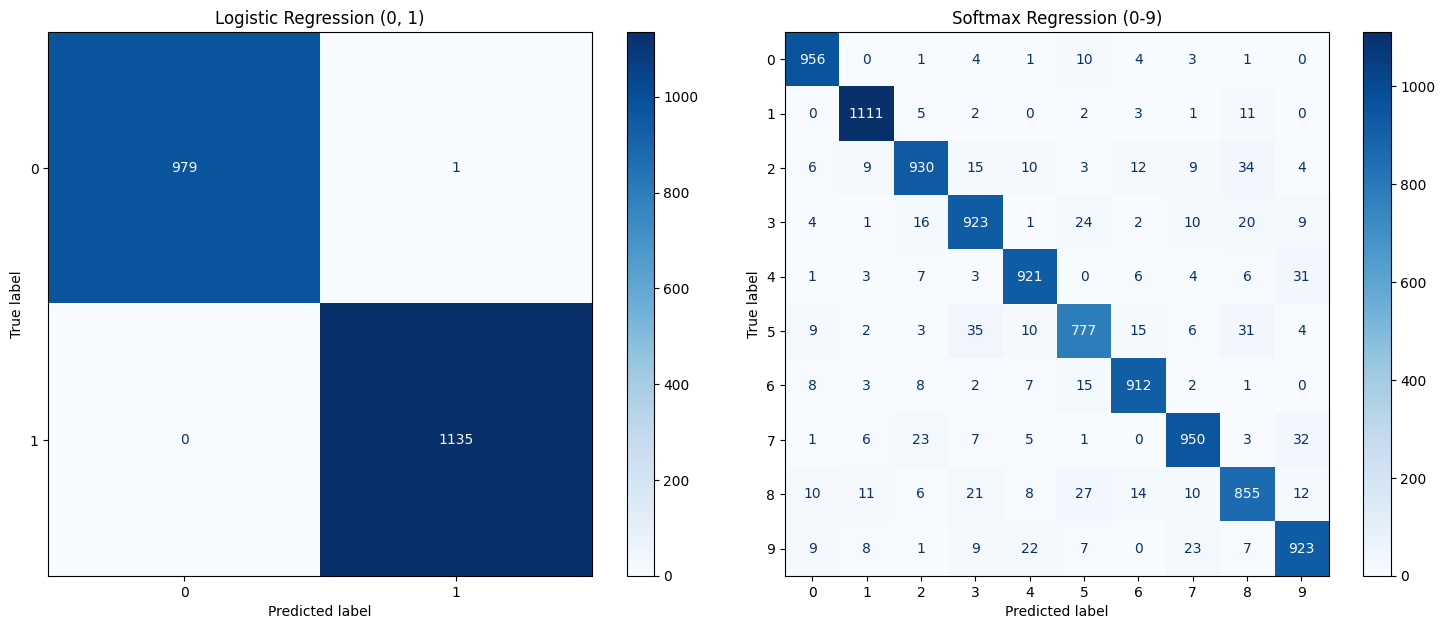

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ConfusionMatrixDisplay.from_predictions(y_test_binary, y_pred_binary, ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Logistic Regression (0, 1)")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_softmax, ax=axes[1], cmap="Blues", values_format="d")
axes[1].set_title("Softmax Regression (0-9)")

plt.tight_layout()
plt.show()

## 8. So sánh kết quả

In [16]:
print(f"{'Metric':<20}{'Logistic':<15}{'Softmax':<15}")
print("-" * 50)
metrics = {
    "Accuracy": accuracy_score,
    "Precision": precision_score,
    "Recall": recall_score,
    "F1-score": f1_score
}

for name, metric in metrics.items():
    if name == "Accuracy":
        score_binary = metric(y_test_binary, y_pred_binary)
        score_softmax = metric(y_test, y_pred_softmax)
    else:
        score_binary = metric(y_test_binary, y_pred_binary, average="macro", zero_division=0)
        score_softmax = metric(y_test, y_pred_softmax, average="macro", zero_division=0)

    print(
        f"{name:<20}"
        f"{score_binary:<15.4f}"
        f"{score_softmax:<15.4f}"
    )

Metric              Logistic       Softmax        
--------------------------------------------------
Accuracy            0.9995         0.9258         
Precision           0.9996         0.9248         
Recall              0.9995         0.9247         
F1-score            0.9995         0.9247         
